# 1.Config do Uv venv e Instalação das Libs

## UV

In [ ]:
from IPython.display import HTML, display

def set_css():
  display(HTML('''
  <style>
    pre {
        white-space: pre-wrap;
    }
  </style>
  '''))
get_ipython().events.register('pre_run_cell', set_css)

In [5]:
# Install UV
!curl -LsSf https://astral.sh/uv/install.sh | sh

downloading uv 0.12.24 x86_64-unknown-linux-gnu
installing to /home/marco-santos/.local/bin
  uv
  uvx
everything's installed!


In [6]:
# Executar no terminal fora do Jupyter notebook, para o compliador selecionar o .venv e instalar o kernel
%uv venv --python 3.12 --seed

/home/marco-santos/Documents/1.Pré-pcc/5.Execução/2.code/.venv/bin/python: No module named uv
Note: you may need to restart the kernel to use updated packages.


In [ ]:
# !source .venv/bin/activate

In [4]:
!uv run python -c "import sys; print(sys.prefix)"


/bin/bash: line 1: uv: command not found


In [ ]:
!uv pip install llama-cpp-python --extra-index-url https://abetlen.github.io/llama-cpp-python/whl/cpu

# Instala o llama-cpp-python pré-compilado com suporte a CUDA (GPU)
# !uv pip install llama-cpp-python --only-binary=llama-cpp-python --force-reinstall --index-strategy unsafe-best-match --extra-index-url https://abetlen.github.io/llama-cpp-python/whl/cu125

!uv pip install huggingface_hub

!uv pip install langchain-text-splitters

!uv pip install ipywidgets

#🛠️ Solução 1: Sincronizar o ambiente e Reiniciar o Ambiente de Execução (Recomendado)
#O segredo no Colab é forçar a atualização do NumPy e SciPy juntos usando o uv e depois reiniciar o ambiente de execução para que o Python limpe a memória antiga.
# Após isso, reinicie a sessão e execute as importações
# !uv pip install --system --upgrade numpy scipy

# uv pip install llama-cpp-python --extra-index-url https://abetlen.github.io/llama-cpp-python/whl/cpu huggingface_hub langchain-text-splitters ipywidgets

/bin/bash: line 1: uv: command not found
/bin/bash: line 1: uv: command not found
/bin/bash: line 1: uv: command not found
/bin/bash: line 1: uv: command not found


## Pip

In [1]:
print("ruN")

ruN


In [ ]:
# !uv pip install llama-cpp-python --extra-index-url https://abetlen.github.io/llama-cpp-python/whl/cpu

# Instala o llama-cpp-python pré-compilado com suporte a CUDA (GPU)
!pip install llama-cpp-python --only-binary=llama-cpp-python --force-reinstall --extra-index-url https://abetlen.github.io/llama-cpp-python/whl/cu125

!pip install huggingface_hub

!pip install langchain-text-splitters


#🛠️ Solução 1: Sincronizar o ambiente e Reiniciar o Ambiente de Execução (Recomendado)
#O segredo no Colab é forçar a atualização do NumPy e SciPy juntos usando o uv e depois reiniciar o ambiente de execução para que o Python limpe a memória antiga.
# Após isso, reinicie a sessão e execute as importações
# !pip install --system --upgrade numpy scipy


Looking in indexes: https://pypi.org/simple, https://abetlen.github.io/llama-cpp-python/whl/cu125
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 GB 758.2 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.9/134.9 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 59.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.6/45.6 kB 4.3 MB/s eta 0:00:00
  Attempting uninstall: typing-extensions
    Found existing installation: typing_extensions 4.16.0
    Uninstalling typing_extensions-4.16.0:
      Successfully uninstalled typing_extensions-4.16.0
  Attempting uninstall: numpy
    Found existing installation: numpy 2.1.3
    Uninstalling numpy-2.1.3:
      Successfully uninstalled numpy-2.1.3
  Attempting uninstall: MarkupSafe
    Found existing installation: MarkupSafe 3.0.3
    Uninstalling MarkupSafe-3.0.3:
      Successfully uninstalled MarkupSaf

# 2.Simplificação

## 2.1.Segmentação

**Passos**


1.   Abrir o arquivo convertido em markdown (.md)
2.   executar a segmentação por cabeçalho markdown
3.  Executar a segmentação recursiva de acordo com o menor contexto dos modelos, de forma a evitar alucinação. Uma **Possível estratégia** seria enviar um pouco do contexto anteior, se chunk estiver na mesma sessão.
4. Guardar e Salvar em um Json
5. Realizar leitura sequencial e salvar no json a simplificação.
6. Após a avaliação e análise, juntar tudo num único documento, reconstruindo os titúlos das sessões e subsessões.



In [8]:
# # 1.Abrir o arquivo convertido em markdown (.md)
# from google.colab import drive
# drive.mount('/content/drive')


In [2]:
from langchain_text_splitters.markdown import MarkdownHeaderTextSplitter
from langchain_text_splitters.character import RecursiveCharacterTextSplitter
import json
import os
from pathlib import Path


CURRENT_PATH = Path.cwd()

def load_data(path) -> str:
  with open(path, 'r', encoding="utf-8") as markdown_original_file:
    loaded_doc = markdown_original_file.read()
  return loaded_doc


def split_doc(text: str, domain: str)-> json:

  if domain != "law":
    headers_to_split_on = [
      ("#", "Header 1"),
      ("##", "Header 2"),
    ]
    
  else:
    # Devido a diferença do padrão de escrita de lei, será adicionado uma segmendação extra por Header 3
    headers_to_split_on = [
      ("#", "Header 1"),
      ("##", "Header 2"),
      ("###", "Header 3"),
    ]
  markdown_splitter = MarkdownHeaderTextSplitter(
    headers_to_split_on=headers_to_split_on,
    strip_headers=False
  )

  markdown_splitted = [
    doc.page_content for doc in markdown_splitter.split_text(text)
  ]

  markdown_splitted = _break_large_chunks(markdown_splitted)

  return markdown_splitted

def _break_large_chunks(chunk_list: list[str], chunk_size=8000):
  """
  Se o chunk > que 8000, quebro ele no meio. E adiciono na nova lista,
  """

  new_list = []
  recursive_splitter = RecursiveCharacterTextSplitter(
    chunk_size=chunk_size,
    chunk_overlap=0
  )


  for chunk in chunk_list:
    if len(chunk) <= chunk_size:
      new_list.append(chunk)
    else:
      recursive_chunks = recursive_splitter.split_text(chunk)
      new_list.extend(each_chunk for each_chunk in recursive_chunks)

  return new_list

def _get_file_path(file_name: str) -> Path:
   return CURRENT_PATH / "paired_original_simplified_chunked_docs" / file_name

def _export_chunks_to_json(chunks: list[str], file_name) -> dict[str, dict[str, dict]]:
  chunks_dict = {str(i): {"original_chunk":chunk, "simplified_chunks_by_model":{}} for i,chunk in enumerate(chunks)}

  # O operador "/" da classe pathlib.Path() junta os elementos adaptando as barras para Windows ou Linux
  
  file_path = _get_file_path(file_name)

  if file_path.is_file():
      print(f"O arquivo {file_name}.json já existe! Pulando a gravação para não sobrescrever.")
      raise FileExistsError()
  
  # 2. o pathlib cria toda a estrutura de pastas até chegar ao arquivo (.parent)
  file_path.parent.mkdir(parents=True, exist_ok=True)

  with open(file_path, "w", encoding="utf-8") as file:
    json.dump(chunks_dict, file, indent=4, ensure_ascii=False)

  return chunks_dict

def open_chunks(file_name: str) -> dict["int", str]:

  file_path = _get_file_path(file_name)
  
  with open(file_path, 'r', encoding="UTF-8") as file:
    loaded_json_chunks = json.load(file)

  return loaded_json_chunks

def save_current_simplification_state(chunks: list[str], file_name) -> bool:
  file_path = _get_file_path(file_name)

  if file_path.is_file():
    with open(file_path, 'w', encoding="UTF-8") as file:
      json.dump(chunks, file, indent=4, ensure_ascii=False)

    return True

  print(f"O arquivo {file_name}.json não existe, não é possivel salvar o estado atual.")
  raise FileNotFoundError()

In [10]:
# continuar agora da parte do recursive text split, entendendo o quanto de characteres e se não seria melhor por Token Text Spliter
from pathlib import Path

user_home = Path.home()

markdown_taget_files_path = [
    {"path":f"{user_home}/Documentos/0.Pessoal/1.Pré-pcc/5.Execução/documentos curados/markdown/5.manual_dsm5_reduzido/5.manual_dsm5_reduzido.md", "domain": "health"},
    {"path": f"{user_home}/Documentos/0.Pessoal/1.Pré-pcc/5.Execução/documentos curados/markdown/7.BENEFÍCIO DE PRESTAÇÃO CONTINUADA DE ASSISTÊNCIA SOCIAL (BPC-LOAS)/7.BENEFÍCIO DE PRESTAÇÃO CONTINUADA DE ASSISTÊNCIA SOCIAL (BPC-LOAS).md", "domain":"administrative"},
    {"path": f"{user_home}/Documentos/0.Pessoal/1.Pré-pcc/5.Execução/documentos curados/markdown/10.pneei/10.cadernos-pedagogicos-pneei-vol-6-completo.md", "domain":"education"},
    {"path": f"{user_home}/Documentos/0.Pessoal/1.Pré-pcc/5.Execução/documentos curados/markdown/3.lei_13977/3.lei_13977.md", "domain":"law"}, # vou ter que usar itens diferentes para a divisão. Devido a distribuição diferente do texto. A divisão até o header 3 (###), pois não fica nem texto demais e nem de menos em cada chunk. Não dividir por artigo (art #º), senão os chunks ficarão pequenos de mais.

]

paired_docs_name = [
    "5.chunked_manual_dsm5.json",
    "7.chunked_LOAS.json",
    "10. chunked_pneei.json",
    "3.chunked_lei_13977.json"
]

# target_doc = markdown_taget_files_path[3]
# target_chunked_docs_folder = paired_docs_name[3]

# doc_splitted = split_doc(load_data(target_doc.get("path")), target_doc.get("domain"))

# _export_chunks_to_json(doc_splitted, target_chunked_docs_folder)

# 2.2.Inference

## 2.2.1. Config

In [3]:

from llama_cpp import Llama
from huggingface_hub import hf_hub_download


def set_model(model_path, thinking=False) -> Llama:

  if not thinking:
    # 1. Carrega o seu modelo GGUF
    llm = Llama(
      model_path=model_path,
      # n_threads=6,
      n_ctx=16048,           # Diminuir de 4096/8192 para 2048 reduz radicalmente o uso de RAM
      # n_batch=512,        # Tamanho do lote de processamento
      # type_k=1,           # Quantiza a chave do KV cache para Q8_0 (economiza RAM)
      # type_v=1,           # Quantiza o valor do KV cache para Q8_0
      use_mmap=True,        # Carrega o arquivo via mmap (carregamento instantâneo)
      use_mlock=False,      # Impede o travamento de toda a RAM pelo processo
      n_gpu_layers=-1,      # Descarrega todas as camadas possíveis na GPU
      # flash_attn=True       # CRUCIAL: Ativa Flash Attention para economizar RAM no contexto longo
    )

  else:
     # 1. Carrega o seu modelo GGUF sem o thiking
    llm = Llama(
      model_path=model_path,
      # n_threads=6,
      n_ctx=16048,           # Diminuir de 4096/8192 para 2048 reduz radicalmente o uso de RAM
      # n_batch=512,        # Tamanho do lote de processamento
      # type_k=1,           # Quantiza a chave do KV cache para Q8_0 (economiza RAM)
      # type_v=1,           # Quantiza o valor do KV cache para Q8_0
      use_mmap=True,        # Carrega o arquivo via mmap (carregamento instantâneo)
      use_mlock=False,      # Impede o travamento de toda a RAM pelo processo
      n_gpu_layers=-1,      # Descarrega todas as camadas possíveis na GPU
      # flash_attn=True,       # CRUCIAL: Ativa Flash Attention para economizar RAM no contexto longo
      chat_template_kwargs={"enable_thinking": False},      # Carrega o modelo desativando a flag de raciocínio no template de chat
      reasoning_budget=0 # Força o interpretador a ignorar ou não alocar tokens para o bloco de pensamento
    )


  return llm



def generate_streamed_text_for_all(llm_param: Llama, target_text: str) -> str:
  import sys


  # 2. Insere as informações apenas em uma estrutura/lista simples (sem formatar string)

  system_prompt = """
  Você é um modelo de linguagem especializado na conversão de textos para textos simplificados. Sua tarefa é converter documentos para linguagem simples sem remover informações importantes. Responda com um novo documento em Português Brasileiro.

  **Passos para simplificar um documento**
  - Inicie o documento pelas informações mais importantes
  - Mantenha o mesmo significado geral do texto e dos parágrafos
  - Encurte as sentenças com mais de 14 palavras
  - Remova a redundância de todas as sentenças
  - Escreva todas as frases na ordem direta, sujeito, verbo e objeto
  - Escreva na voz ativa em vez da passiva
  - Substitua palavras complexas e jargões por palavras de mesmo significado, ou explique o significado de palavras complexas e jargões
  - Remova palavras que não possuem função na frase
  - Sempre adicione quebras de linha para facilitar a leitura
  - Escreva o nome completo antes de siglas
  - Evite palavras estrangeiras pouco comuns em português do Brasil

  **Objetivo**: gere um documento mais simples seguindo esses passos, mas não sumarize, mantenha todas as informações relevantes.
  **Resposta**: retorne apenas o novo texto gerado em Português, NUNCA faça comentários sobre sua implementação.
  """

  # texto_alvo = """
  # Aqui está o texto alvo:

  # Texto alvo:

  # <texto_alvo>
  # "A PRESIDENTA DA REPÚBLICA Faço saber que o Congresso Nacional decreta e eu sanciono a seguinte Lei:

  # Art. 1º Esta Lei institui a Política Nacional de Proteção dos Direitos da Pessoa com Transtorno do Espectro Autista e estabelece diretrizes para sua consecução.

  # § 1º Para os efeitos desta Lei, é considerada pessoa com transtorno do espectro autista aquela portadora de síndrome clínica caracterizada na forma dos seguintes incisos I ou II:

  # I - deficiência persistente e clinicamente significativa da comunicação e da interação sociais, manifestada por deficiência marcada de comunicação verbal e não verbal usada para interação social; ausência de reciprocidade social; falência em desenvolver e manter relações apropriadas ao seu nível de desenvolvimento;

  # II - padrões restritivos e repetitivos de comportamentos, interesses e atividades, manifestados por comportamentos motores ou verbais estereotipados ou por comportamentos sensoriais incomuns; excessiva aderência a rotinas e padrões de comportamento ritualizados; interesses restritos e fixos.

  # § 2º A pessoa com transtorno do espectro autista é considerada pessoa com deficiência, para todos os efeitos legais.

  # § 3º Os estabelecimentos públicos e privados referidos na Lei nº 10.048, de 8 de novembro de 2000, poderão valer-se da fita quebra-cabeça, símbolo mundial da conscientização do transtorno do espectro autista, para identificar a prioridade devida às pessoas com transtorno do espectro autista.            (Incluído pela Lei nº 13.977, de 2020)"
  # </texto_alvo>
  # """

  texto_alvo = f"""
  Aqui está o texto alvo:

  Texto alvo:

  <texto_alvo>
  {target_text}
  </texto_alvo>"""

  messages = [
      {
          "role": "system",
          "content": system_prompt
      },
      {
          "role": "user",
          "content": f"Aqui está o texto alvo:\n\n<texto_alvo>\n{texto_alvo}\n</texto_alvo>"
          }
  ]

  # 3. Executando o streaming pelo método create_chat_completion
  response_stream = llm_param.create_chat_completion(
      messages=messages,
      max_tokens=8192,
      stream=True
  )

  # print("Resposta: ", end="")
  response_text = ""

  # 4. Consumindo o stream em tempo real
  for chunk in response_stream:
      # No formato ChatCompletion, o texto vem no campo delta['content']
      delta = chunk["choices"][0]["delta"]

      if "content" in delta:
          text_chunk = delta["content"]
          response_text += text_chunk

          # Exibe imediatamente no terminal
          print(text_chunk, end="")
          sys.stdout.flush()

  return response_text

In [4]:
from llama_cpp import Llama
import time


def simplify_json_chunks(paired_file_name: str, model_name: str, llm_param: Llama, attempt_number:str):

    if attempt_number == 1:

        if model_name == "gemma-4-E2B_q4_0-it.gguf" and paired_file_name == paired_docs_name[0]:
            print("Documento já simplificado neste nível de teste")
            return

        if model_name == "qwen2.5-7b-instruct-q4_k_m.gguf" and paired_file_name == paired_docs_name[1]:
            print("Documento já simplificado neste nível de teste")
            return
            
        loaded_json_chunks = open_chunks(paired_file_name)

        # response = generate_streamed_text_for_all(llm_param=llm_gemma_4_E2B, target_text=loaded_json_chunks["0"]["original_chunk"])

        inference_time_for_all_chunks = 0

        for key in loaded_json_chunks.keys():
            if key == "inference_time_for_all_chunks" or (not str(key).isdigit()):
                break
            print(f"Simplificando o **{key}** chunk do arquivo")
            
            # Inicia o cronômetro
            start_inference_time = time.perf_counter()
            response = generate_streamed_text_for_all(llm_param=llm_param, target_text=loaded_json_chunks[key]["original_chunk"])
            end_inference_time = time.perf_counter()

            total_inference_time = end_inference_time - start_inference_time
            inference_time_for_all_chunks += total_inference_time

            minutes = int(total_inference_time // 60)
            seconds = f"{total_inference_time % 60:0.3f}"
                
            loaded_json_chunks[key]["simplified_chunks_by_model"][model_name] = {
                "simplified_chunk": response,
                "execution_time_in_seconds": total_inference_time,
                "execution_time_minute_formated": f"{minutes}m {seconds}s"
            }

            save_current_simplification_state(loaded_json_chunks, paired_file_name)
    else:
        raise Exception("""SE É A SEGUNDA ETAPA DE SIMPLIFICAÇÃO, SE HOUVE ALTERAÇÃO NO MODELO, OU PROMPT, PARAMETROS, CHUNK STRATEGY OU ALGO ASSIM, REMOVA A FERIFICAÇÃO 
        \"if model_name == model_name_gemma_4_E2B and file_index == 0:\"""")


    inference_time_for_all_chunks_in_minutes = int(inference_time_for_all_chunks // 60)
    inference_time_for_all_chunks_in_seconds = f"{inference_time_for_all_chunks % 60:0.3f}"

    loaded_json_chunks["inference_time_for_all_chunks"][model_name] = {
        "execution_time_in_seconds": inference_time_for_all_chunks,
        "execution_time_minute_formated": f"{inference_time_for_all_chunks_in_minutes}m {inference_time_for_all_chunks_in_seconds}s"
        }

    save_current_simplification_state(loaded_json_chunks, paired_file_name)

## 2.2.2. Execute all models for all registered files

In [5]:
def run_in_bath(model_name, llm_param):
    ATTEMPT_NUMBER = 1 # Primeira tentativa, em caso de alterar prompt, estratégia de chunk, adcinoar modelos, incrementear em 1 e atualizar a função simplify_json_chunks() com a lógica necessária para não haver retrabalho
    for file_name in paired_docs_name:
        print(f"Realizando inferência com o modelo **{model_name}** para simplificação do arquivo **{file_name}**")
        simplify_json_chunks(paired_file_name=file_name, model_name=model_name, llm_param=llm_param, attempt_number=ATTEMPT_NUMBER)


In [ ]:
from huggingface_hub import hf_hub_download


# Gemma 4 E2B
model_name_gemma_4_E2B = "gemma-4-E2B_q4_0-it.gguf"

model_path_gemma_4_E2B = hf_hub_download(
    repo_id="google/gemma-4-E2B-it-qat-q4_0-gguf",
    filename=model_name_gemma_4_E2B
)

llm_gemma_4_E2B = set_model(model_path_gemma_4_E2B)

run_in_bath(model_name=model_name_gemma_4_E2B, llm_param=llm_gemma_4_E2B)
llm_gemma_4_E2B = None # Retirando o modelo da memória RAM para não crashar o PC



# Qwen 2.5 7B

model_name_Qwen2_5_7B = "qwen2.5-7b-instruct-q4_k_m.gguf"
model_path_Qwen2_5_7B = hf_hub_download(
    repo_id="paultimothymooney/Qwen2.5-7B-Instruct-Q4_K_M-GGUF",
    filename=model_name_Qwen2_5_7B
)

llm_qwen2_5_7B = set_model(model_path_Qwen2_5_7B)

run_in_bath(model_name=model_name_Qwen2_5_7B, llm_param=llm_qwen2_5_7B)

llm_qwen2_5_7B = None # Retirando o modelo da memória RAM para não crashar o PC



# llmama 3.2 3B

model_name_llama_3_2_3B = "Llama-3.2-3B-Instruct-Q8_0.gguf"
model_path_llama_3_2_3B = hf_hub_download(
    repo_id="bartowski/Llama-3.2-3B-Instruct-GGUF",
    filename=model_name_llama_3_2_3B
)

llm_llama_3_2_3B = set_model(model_path_llama_3_2_3B)

run_in_bath(model_name=model_name_llama_3_2_3B, llm_param=llm_llama_3_2_3B)

llm_llama_3_2_3B = None # Retirando o modelo da memória RAM para não crashar o PC

In [32]:
def sum_models_time_if_needed():
    CURRENT_DOC = paired_docs_name[3]

    loaded_json_chunks = open_chunks(CURRENT_DOC)

    total_inference_time = {
        "gemma-4-E2B_q4_0-it.gguf": 0.0,
        "qwen2.5-7b-instruct-q4_k_m.gguf": 0.0,
        "Llama-3.2-3B-Instruct-Q8_0.gguf": 0.0
    }

    for key in loaded_json_chunks.keys():

        for model_key in total_inference_time.keys():
            if key != "inference_time_for_all_chunks":
                # print(f"{key}--{model_key}--{loaded_json_chunks[key]["simplified_chunks_by_model"][model_key]["execution_time_in_seconds"]}")
                # print(total_inference_time)
                total_inference_time[model_key] += loaded_json_chunks[key]["simplified_chunks_by_model"][model_key]["execution_time_in_seconds"]
            else:
                inference_time_for_all_chunks_in_minutes = int(total_inference_time[model_key] // 60)
                inference_time_for_all_chunks_in_seconds = f"{total_inference_time[model_key] % 60:0.3f}"
                
                loaded_json_chunks["inference_time_for_all_chunks"][model_key] = {
                    "execution_time_in_seconds": total_inference_time[model_key],
                    "execution_time_minute_formated":  f"{inference_time_for_all_chunks_in_minutes}m {inference_time_for_all_chunks_in_seconds}s"
                }
            
    save_current_simplification_state(loaded_json_chunks, CURRENT_DOC)

sum_models_time_if_needed()

## [BACKUP]google/gemma-4-E2B-it-qat-q4_0-gguf
 - **context window** of up to
128K tokens

https://huggingface.co/google/gemma-4-E2B-it-qat-q4_0-gguf

<sup>Esse modelo tem 2,3 bilhões de parâmetros ativos para o processamento de texto, mas chega a um total de 5,1 bilhões de parâmetros totais quando somadas as camadas de processamento multimodal.
</sup>



> Para mais informações acesse: https://ai.google.dev/gemma/docs/core?hl=pt-br




![gemma.jpg](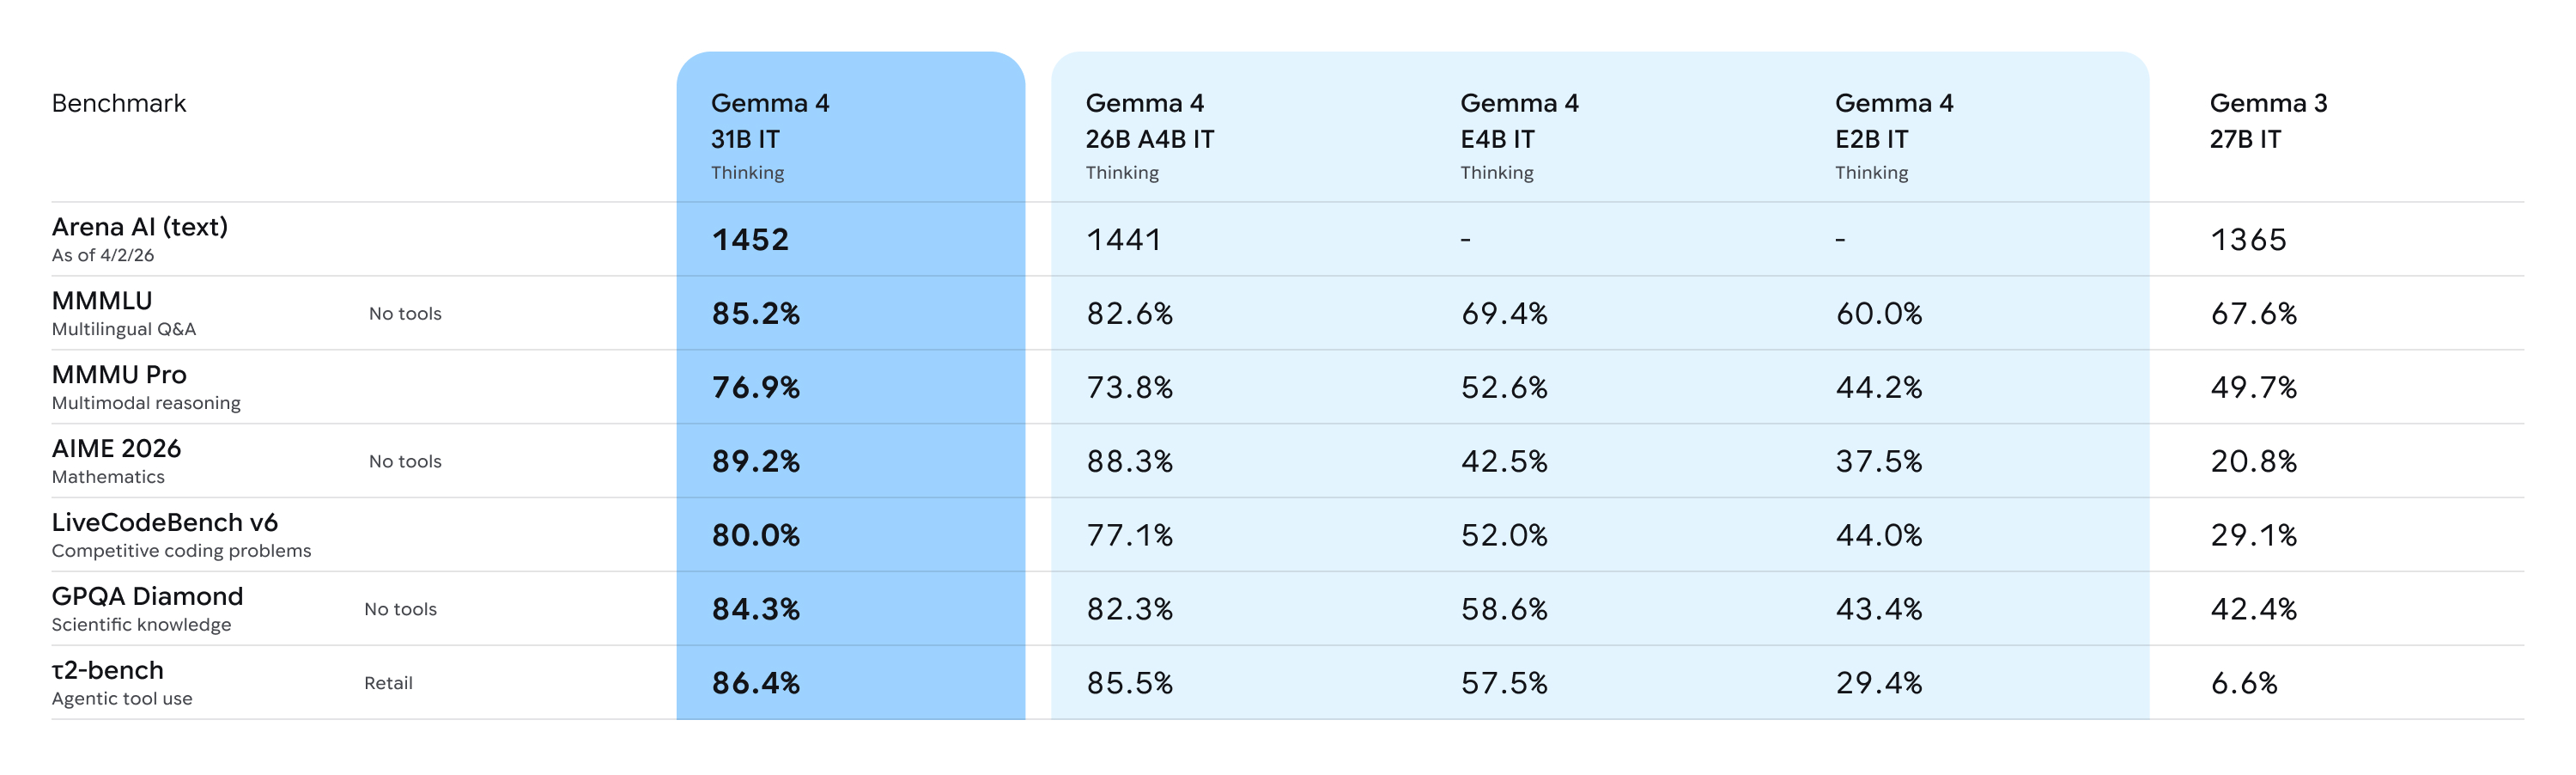)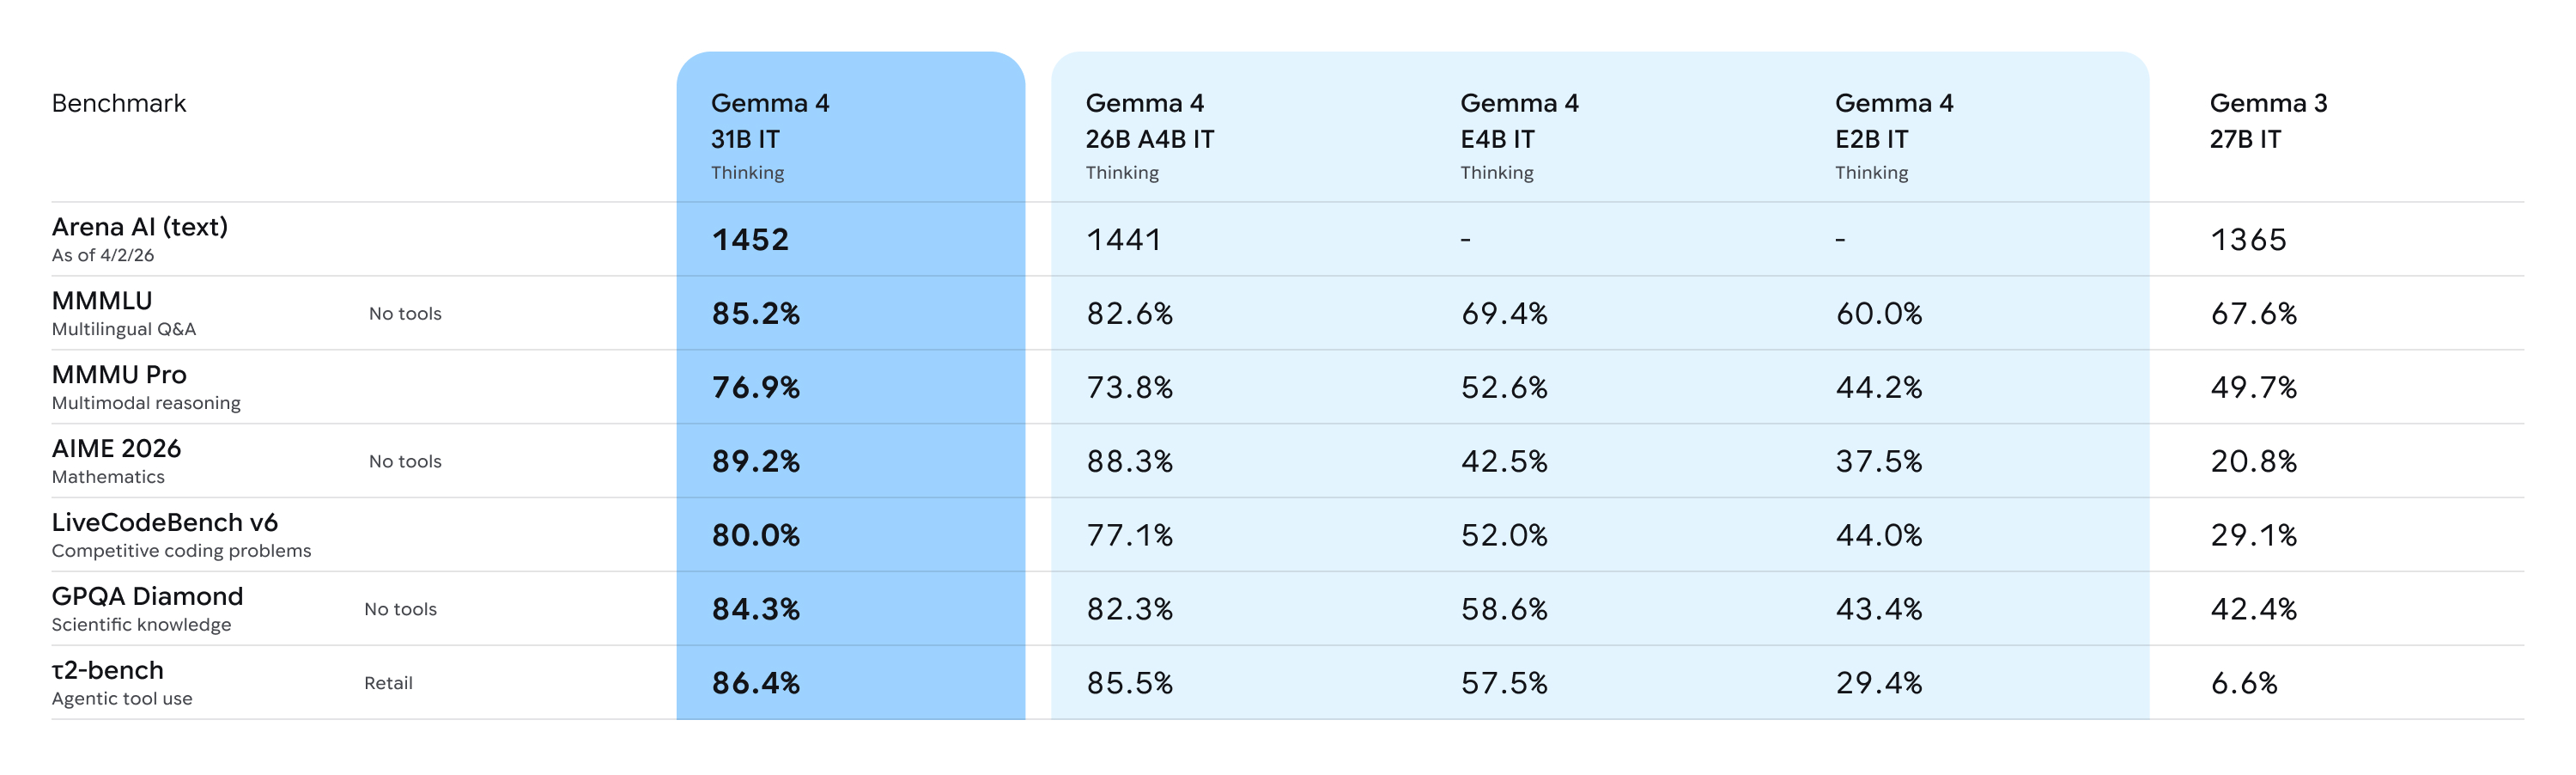

In [ ]:
model_name_gemma_4_E2B = "gemma-4-E2B_q4_0-it.gguf"

model_path_gemma_4_E2B = hf_hub_download(
    repo_id="google/gemma-4-E2B-it-qat-q4_0-gguf",
    filename=model_name_gemma_4_E2B
)



In [ ]:
llm_gemma_4_E2B = set_model(model_path_gemma_4_E2B)

In [43]:
response = generate_streamed_text_for_all(llm_param=llm_gemma_4_E2B, target_text="Hi")


AttributeError: 'NoneType' object has no attribute 'create_chat_completion'

In [ ]:
print(59.260898546000135+117.78672560300038+12.227001790000031+172.85161347200028+215.1365615169998+74.017637207+25.379760994999742+169.9691623710005+49.14121072099988)

inference_time_for_all_chunks=895.7705722220007

inference_time_for_all_chunks_in_minutes = int(inference_time_for_all_chunks // 60)
inference_time_for_all_chunks_in_seconds = f"{inference_time_for_all_chunks % 60:0.3f}"

print(inference_time_for_all_chunks_in_minutes)
print(inference_time_for_all_chunks_in_seconds)

895.7705722220007
14
55.771


## [BACKUP] Qwen2.5-7B-Instruct-Q4_K_M-GGUF


- **Context Window**: 128K tokens
- **Generate**: up to 8K tokens.

<sub>The current `config.json` is set for context length up to **32,768** tokens</sub>



https://huggingface.co/paultimothymooney/Qwen2.5-7B-Instruct-Q4_K_M-GGUF


In [ ]:
from huggingface_hub import hf_hub_download

model_path_Qwen2_5_7B = hf_hub_download(
    repo_id="paultimothymooney/Qwen2.5-7B-Instruct-Q4_K_M-GGUF",
    filename="qwen2.5-7b-instruct-q4_k_m.gguf"
)


qwen2.5-7b-instruct-q4_k_m.gguf: reconstructing file:   0%|          |  0.00B / 4.68GB            

qwen2.5-7b-instruct-q4_k_m.gguf: downloading bytes:           |  0.00B            

In [ ]:
llm_qwen2_5_7B = set_model(model_path_qwen2_5_7B)

llama_model_loader: loaded meta data with 34 key-value pairs and 339 tensors from /root/.cache/huggingface/hub/models--paultimothymooney--Qwen2.5-7B-Instruct-Q4_K_M-GGUF/snapshots/dc9a6adc76b4bc8a2372103a899d2e0efc1cf142/qwen2.5-7b-instruct-q4_k_m.gguf (version GGUF V3 (latest))
llama_model_loader: Dumping metadata keys/values. Note: KV overrides do not apply in this output.
llama_model_loader: - kv   0:                       general.architecture str              = qwen2
llama_model_loader: - kv   1:                               general.type str              = model
llama_model_loader: - kv   2:                               general.name str              = Qwen2.5 7B Instruct
llama_model_loader: - kv   3:                           general.finetune str              = Instruct
llama_model_loader: - kv   4:                           general.basename str              = Qwen2.5
llama_model_loader: - kv   5:                         general.size_label str              = 7B
llama_model_loader

In [ ]:
response = generate_streamed_text_for_all(llm_param=llm_Qwen2_5_7B)

Resposta: 

llama_perf_context_print:        load time =  256038.15 ms
llama_perf_context_print: prompt eval time =  256036.03 ms /   784 tokens (  326.58 ms per token,     3.06 tokens per second)
llama_perf_context_print:        eval time =       0.00 ms /     1 runs   (    0.00 ms per token,      inf tokens per second)
llama_perf_context_print:       total time =  256040.39 ms /   785 tokens
llama_perf_context_print:    graphs reused =          0


## [BACKUP] Llama-3.2-3B-Instruct-GGUF

- **Context Window**: 128K tokens
- **Generate**: up to 8K tokens.

https://huggingface.co/bartowski/Llama-3.2-3B-Instruct-GGUF


In [ ]:
from huggingface_hub import hf_hub_download

model_path_llama_3_2_3B = hf_hub_download(
    repo_id="bartowski/Llama-3.2-3B-Instruct-GGUF",
    filename="Llama-3.2-3B-Instruct-Q8_0.gguf"
)

Llama-3.2-3B-Instruct-Q8_0.gguf: reconstructing file:   0%|          |  0.00B / 3.42GB            

Llama-3.2-3B-Instruct-Q8_0.gguf: downloading bytes:           |  0.00B            

In [ ]:
llm_llama_3_2_3B = set_model(model_path_llama_3_2_3B)

llama_model_loader: loaded meta data with 35 key-value pairs and 255 tensors from /root/.cache/huggingface/hub/models--bartowski--Llama-3.2-3B-Instruct-GGUF/snapshots/5ab33fa94d1d04e903623ae72c95d1696f09f9e8/Llama-3.2-3B-Instruct-Q8_0.gguf (version GGUF V3 (latest))
llama_model_loader: Dumping metadata keys/values. Note: KV overrides do not apply in this output.
llama_model_loader: - kv   0:                       general.architecture str              = llama
llama_model_loader: - kv   1:                               general.type str              = model
llama_model_loader: - kv   2:                               general.name str              = Llama 3.2 3B Instruct
llama_model_loader: - kv   3:                           general.finetune str              = Instruct
llama_model_loader: - kv   4:                           general.basename str              = Llama-3.2
llama_model_loader: - kv   5:                         general.size_label str              = 3B
llama_model_loader: - kv   

In [ ]:
response = generate_streamed_text_for_all(llm_llama_3_2_3B)